# **Hate Speech Classification**

Tujuan project: Membangun model klasifikasi biner menggunakan TF-IDF dan Support Vector Machine yang mampu mengklasifikasikan teks berbahasa Indonesia menjadi kelas hate speech dan non-hate speech.


## **Import Library**

In [1]:
import pandas as pd
import numpy as np
import re

from collections import Counter
import matplotlib.pyplot as plt

## **Load Dataset**

In [5]:
# Membaca dataset hate speech
df = pd.read_csv('../dataset/raw/data.csv', encoding='latin-1')

In [6]:
# Menampilkan informasi struktur dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13169 entries, 0 to 13168
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Tweet          13169 non-null  object
 1   HS             13169 non-null  int64 
 2   Abusive        13169 non-null  int64 
 3   HS_Individual  13169 non-null  int64 
 4   HS_Group       13169 non-null  int64 
 5   HS_Religion    13169 non-null  int64 
 6   HS_Race        13169 non-null  int64 
 7   HS_Physical    13169 non-null  int64 
 8   HS_Gender      13169 non-null  int64 
 9   HS_Other       13169 non-null  int64 
 10  HS_Weak        13169 non-null  int64 
 11  HS_Moderate    13169 non-null  int64 
 12  HS_Strong      13169 non-null  int64 
dtypes: int64(12), object(1)
memory usage: 1.3+ MB


In [7]:
# Menampilkan 5 baris pertama
df.head()

,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
0,- disaat semua cowok berusaha melacak perhatia...,1,1,1,0,0,0,0,0,1,1,0,0
1,RT USER: USER siapa yang telat ngasih tau elu?...,0,1,0,0,0,0,0,0,0,0,0,0
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",0,0,0,0,0,0,0,0,0,0,0,0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,0,0,0,0,0,0,0,0,0,0,0,0
4,USER USER Kaum cebong kapir udah keliatan dong...,1,1,0,1,1,0,0,0,0,0,1,0


In [8]:
# Menampilkan 5 baris terakhir
df.tail()

,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
13164,USER jangan asal ngomong ndasmu. congor lu yg ...,1,1,1,0,0,0,1,0,0,1,0,0
13165,USER Kasur mana enak kunyuk',0,1,0,0,0,0,0,0,0,0,0,0
13166,USER Hati hati bisu :( .g\n\nlagi bosan huft \...,0,0,0,0,0,0,0,0,0,0,0,0
13167,USER USER USER USER Bom yang real mudah terdet...,0,0,0,0,0,0,0,0,0,0,0,0
13168,"USER Mana situ ngasih("": itu cuma foto ya kuti...",1,1,1,0,0,0,0,0,1,1,0,0


In [9]:
# Menampilkan jumlah data untuk kategori Hate Speech
df.HS.value_counts()

HS
0    7608
1    5561
Name: count, dtype: int64

Label 1 means yes (Hate Speech), 0 mean no (Non-Hate Speech).

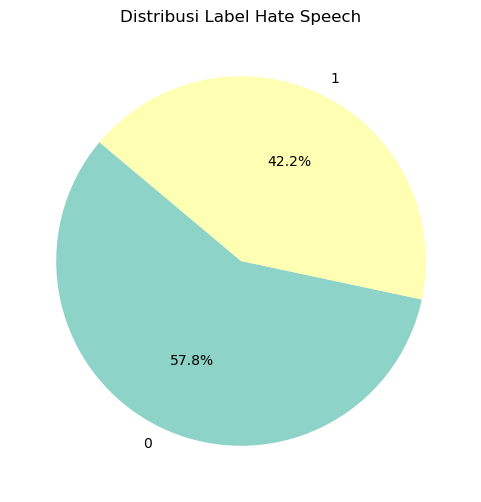

In [10]:
# Visualisasi distribusi label
plt.figure(figsize=(6, 6))

df['HS'].value_counts().plot.pie(
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.Set3.colors,
    labels=df['HS'].value_counts().index
)
plt.title("Distribusi Label Hate Speech")
plt.ylabel('')
plt.show()

In [11]:
# Mengecek jumlah data yang kosong (missing value)
df.isnull().sum()

Tweet            0
HS               0
Abusive          0
HS_Individual    0
HS_Group         0
HS_Religion      0
HS_Race          0
HS_Physical      0
HS_Gender        0
HS_Other         0
HS_Weak          0
HS_Moderate      0
HS_Strong        0
dtype: int64

In [12]:
# Mengecek jumlah data duplikasi
jumlah_duplikat = df.duplicated(subset="Tweet").sum()
print("Jumlah data duplikat:", jumlah_duplikat)

data_duplikat = df[df.duplicated(keep=False)].copy()
data_duplikat

Jumlah data duplikat: 146


,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
33,"RT USER: Kelakuan homok jaman now, ngentot aja...",0,1,0,0,0,0,0,0,0,0,0,0
43,#GubernurZamanNow #GusIpulPuti2 #GanjarYasin1 ...,0,0,0,0,0,0,0,0,0,0,0,0
165,Giat Bhabinkamtibmas Brigpol Mbs Sihombing pd ...,0,0,0,0,0,0,0,0,0,0,0,0
182,USER USER USER USER USER USER USER USER USER U...,0,0,0,0,0,0,0,0,0,0,0,0
239,Monyet Turun ke Pemukiman Warga Cibadak Sukabu...,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12793,I added a video to a USER playlist,0,0,0,0,0,0,0,0,0,0,0,0
12952,USER USER USER USER USER USER USER USER USER U...,0,0,0,0,0,0,0,0,0,0,0,0
12953,"SETUJU SAYA,KLAU AHOK DAPAT GELAR SANTRI KEHOR...",1,1,1,0,0,0,0,0,1,1,0,0
12985,USER ahmad dhani yang terhormat paling babi pa...,1,1,1,0,0,0,0,1,0,1,0,0


In [13]:
# Menghitung jumlah data sebelum dihapus
jumlah_sebelum = len(df)

# Menghapus data duplikat, mempertahankan kemunculan pertama
df = df.drop_duplicates(subset="Tweet", keep="first").copy()

# Menghitung jumlah data setelah dihapus
jumlah_setelah = len(df)

print("Jumlah data sebelum dihapus:", jumlah_sebelum)
print("Jumlah baris duplikat yang dihapus:", jumlah_duplikat)
print("Jumlah data setelah dihapus:", jumlah_setelah)

Jumlah data sebelum dihapus: 13169
Jumlah baris duplikat yang dihapus: 146
Jumlah data setelah dihapus: 13023


In [14]:
# Mengambil kolom tweet dan HS
df = df[['Tweet', 'HS']]

# Mengecek ulang bentuk dataset
print("Bentuk dataset:", df.shape)

# Menampilkan 5 baris pertama
df.head()

Bentuk dataset: (13023, 2)


,Tweet,HS
0,- disaat semua cowok berusaha melacak perhatia...,1
1,RT USER: USER siapa yang telat ngasih tau elu?...,0
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,0
4,USER USER Kaum cebong kapir udah keliatan dong...,1


## **Exploratory Data Analysis (EDA)**

KARAKTERISTIK DATA

In [15]:
# Mengecek karakteristik data
eda = df.copy()

# Menghitung karakter dan kata
eda["jumlah_karakter"] = eda["Tweet"].fillna("").astype(str).str.len()
eda["jumlah_kata"] = (eda["Tweet"].fillna("").astype(str).str.split().str.len())

eda[["jumlah_karakter", "jumlah_kata"]].describe().round(2)

,jumlah_karakter,jumlah_kata
count,13023.00,13023.00
mean,114.11,17.26
std,69.12,10.24
min,4.00,1.00
25%,59.00,9.00
50%,100.00,15.00
75%,152.00,23.00
max,561.00,52.00


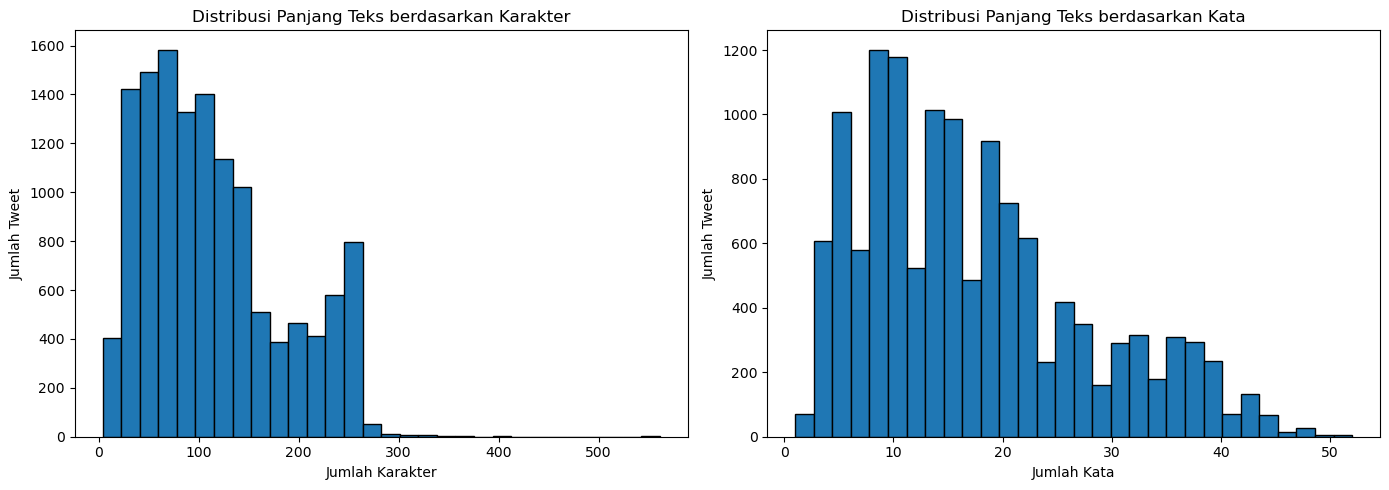

In [16]:
# Visualisasi distribusi panjang teks
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi jumlah karakter
axes[0].hist(eda["jumlah_karakter"], bins=30, edgecolor="black")
axes[0].set_title("Distribusi Panjang Teks berdasarkan Karakter")
axes[0].set_xlabel("Jumlah Karakter")
axes[0].set_ylabel("Jumlah Tweet")

# Distribusi jumlah kata
axes[1].hist(eda["jumlah_kata"], bins=30, edgecolor="black")
axes[1].set_title("Distribusi Panjang Teks berdasarkan Kata")
axes[1].set_xlabel("Jumlah Kata")
axes[1].set_ylabel("Jumlah Tweet")

plt.tight_layout()
plt.show()

KARAKTER KHUSUS

In [17]:
# Distribusi karakter
teks = eda["Tweet"].fillna("").astype(str)

karakteristik = pd.DataFrame({
    "Huruf kapital": teks.str.contains(r"[A-Z]{3,}", regex=True),
    "Mengandung URL": teks.str.contains(r"https?://|www\.", case=False, regex=True),
    "Mengandung mention": teks.str.contains(r"@\w+", regex=True),
    "Mengandung hashtag": teks.str.contains(r"#\w+", regex=True),
    "Tanda baca berulang": teks.str.contains(r"[!?.,]{2,}", regex=True),
    "Mengandung angka": teks.str.contains(r"\d", regex=True)
})

distribusi = pd.DataFrame({
    "Karakteristik": karakteristik.columns,
    "Jumlah Tweet": karakteristik.sum().values,
    "Persentase (%)": (karakteristik.mean().values * 100).round(2)
})

distribusi

,Karakteristik,Jumlah Tweet,Persentase (%)
0,Huruf kapital,9419,72.33
1,Mengandung URL,3,0.02
2,Mengandung mention,0,0.00
3,Mengandung hashtag,1292,9.92
4,Tanda baca berulang,3218,24.71
5,Mengandung angka,4356,33.45


In [18]:
# Statistik panjang teks berdasarkan kelas label
statistik_label = (eda.groupby("HS").agg(
    jumlah_tweet=("Tweet", "count"),
    rata_rata_karakter=("jumlah_karakter", "mean"),
    median_karakter=("jumlah_karakter", "median"),
    rata_rata_kata=("jumlah_kata", "mean"),
    median_kata=("jumlah_kata", "median")
    ).round(2)
)

statistik_label

,jumlah_tweet,rata_rata_karakter,median_karakter,rata_rata_kata,median_kata
HS,,,,,
0,7522,122.85,107.0,18.38,16.0
1,5501,102.16,94.0,15.72,14.0


In [19]:
# Kata dominan
semua_teks = " ".join(eda["Tweet"].dropna().astype(str).str.lower())

# Mengambil rangkaian huruf sebagai kata sederhana
kata = re.findall(r"\b[a-zA-ZÀ-ÿ]+\b", semua_teks)

frekuensi_kata = Counter(kata)

tabel_kata = pd.DataFrame(frekuensi_kata.most_common(20), columns=["Kata", "Frekuensi"])
tabel_kata

,Kata,Frekuensi
0,user,15493
1,yg,2928
2,dan,2712
3,di,2703
4,yang,1992
5,n,1748
6,itu,1704
7,ini,1563
8,ada,1343
9,ya,954


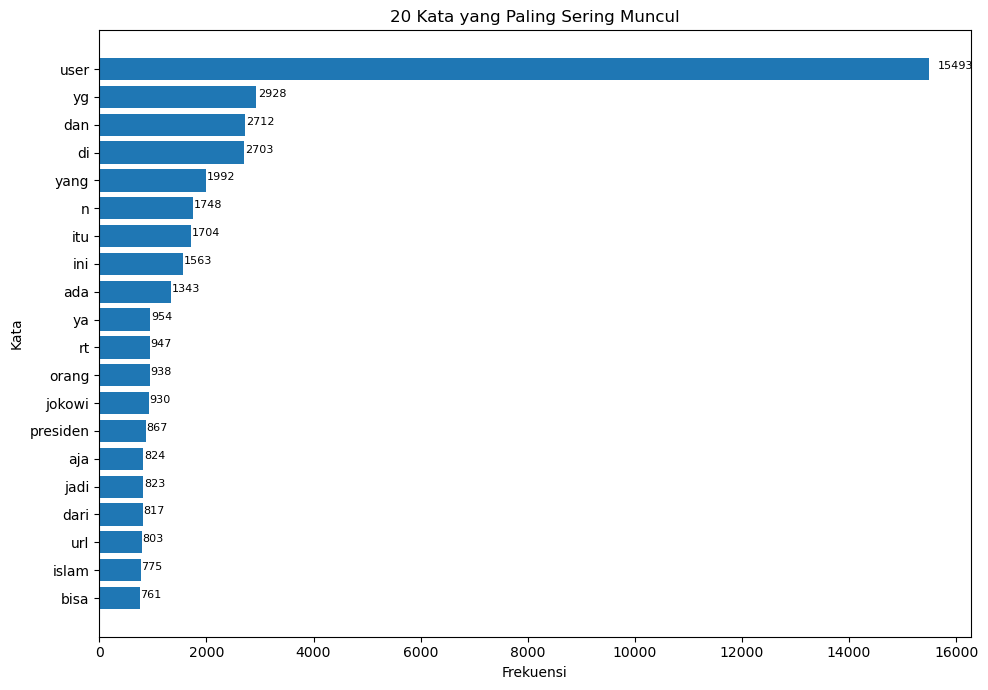

In [30]:
# Visualisasi 20 kata dominan
tabel_plot = tabel_kata.sort_values("Frekuensi")

plt.figure(figsize=(10, 7))
bars=plt.barh(tabel_plot["Kata"], tabel_plot["Frekuensi"])

plt.title("20 Kata yang Paling Sering Muncul")
plt.xlabel("Frekuensi")
plt.ylabel("Kata")

for bar in bars:
  width = bar.get_width()  # Mengambil nilai frekuensi (lebar batang)
  plt.text(
      width + (width * 0.01),  # Posisi X: sedikit di sebelah kanan ujung batang
      bar.get_y()
      + bar.get_height() / 2,  # Posisi Y: di tengah-tengah tinggi batang
      str(int(width)),  # Nilai angka yang akan ditampilkan
      fontsize=8,
  )

plt.tight_layout()
plt.show()

In [31]:
df.to_csv('../dataset/processed/data_eda.csv', index=False)
print("File berhasil disimpan")

File berhasil disimpan
